# Chapitre 14 - Cours 1 : règles d'association et apprentissage non supervisé vu comme supervisé

Ce premier notebook du chapitre 14 couvre les sections 14.1 et 14.2 du livre :

1. ce qui distingue l'apprentissage **non supervisé** de l'apprentissage supervisé ;
2. les **règles d'association** (« analyse du panier de la ménagère ») et l'algorithme **Apriori**,
   appliqués aux données démographiques `marketing` (figure 14.2 du livre) ;
3. l'astuce qui transforme l'**estimation d'une densité** en un problème de **classification**
   supervisée (section 14.2.4, figure 14.3) ;
4. les **règles d'association généralisées** obtenues avec PRIM (sections 14.2.5 à 14.2.7).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch14_non_supervise as ns
set_style()

## 1. Apprentissage supervisé et non supervisé

En apprentissage **supervisé**, on dispose de couples $(x_i, y_i)$ et l'on cherche à prédire
$Y$ à partir de $X$. Le « professeur » (la réponse $y_i$) permet de mesurer la qualité d'une
prédiction, par exemple par la perte quadratique. Formellement, on cherche en chaque $x$ la
valeur

$$\mu(x) = \operatorname*{argmin}_{\theta} \; \mathbb{E}_{Y\mid X=x}\, L(Y, \theta),$$

ce qui est l'éq. (14.1) du livre : on n'étudie que la **loi conditionnelle** de $Y$ sachant $X$.

En apprentissage **non supervisé**, on observe seulement $x_1, \dots, x_N$, réalisations
indépendantes d'un vecteur aléatoire $X \in \mathbb{R}^p$ de densité $g$. Le but est de
**décrire** $g$ : où se concentre la masse de probabilité (modes, régions de forte densité),
quelles variables sont liées entre elles, existe-t-il des groupes naturels, des structures de
faible dimension ?

> **Intuition.** Il n'y a pas de « bonne réponse » à laquelle se comparer : aucune mesure
> d'erreur directe comme l'erreur de test. La validité d'une analyse non supervisée relève
> souvent du jugement de l'utilisateur, ce qui explique la profusion de méthodes heuristiques.

Quand $p$ est petit (1, 2 ou 3), on peut estimer $g$ directement (estimateurs à noyau du
chapitre 6). En grande dimension, c'est hors de portée (fléau de la dimension) et l'on se
contente de résumés :

* des **régions de forte densité** décrites par des conjonctions de conditions simples
  (règles d'association, ce notebook) ;
* des **groupes** d'observations (classification, cours 2) ;
* des **variétés de petite dimension** autour desquelles se concentrent les données
  (ACP, courbes principales, cartes auto-organisatrices, MDS… cours 3).

## 2. Règles d'association

### 2.1 Le problème : trouver des valeurs conjointes fréquentes

On considère $p$ variables **discrètes** $X_1, \dots, X_p$, typiquement des indicatrices
d'achat ($X_j = 1$ si le produit $j$ est dans le panier). Idéalement, on voudrait trouver des
valeurs « prototypes » $v_1, \dots, v_L$ de forte probabilité $\Pr(X = v_l)$. Mais avec beaucoup
de variables, chaque valeur conjointe a une probabilité minuscule : on relâche le problème.

Au lieu d'une valeur exacte, on cherche des sous-ensembles $s_j$ de valeurs pour certaines
variables $j \in \mathcal{J} \subset \{1, \dots, p\}$ tels que

$$\Pr\Big(\bigcap_{j \in \mathcal{J}} \{X_j \in s_j\}\Big) \quad \text{soit grande},$$

c'est l'éq. (14.2) du livre. Une telle conjonction s'appelle une **règle conjonctive** ;
elle décrit un « pavé » de l'espace des variables où la densité est élevée.

### 2.2 Codage en items et support

L'analyse du panier simplifie encore : chaque $s_j$ est soit une **seule** valeur, soit
l'ensemble de toutes les valeurs (la variable n'intervient pas). On code alors chaque couple
(variable, valeur) par une **indicatrice** $Z_k$ ; si la variable $j$ prend $|\mathcal{S}_j|$
valeurs, on obtient $K = \sum_j |\mathcal{S}_j|$ indicatrices appelées **items**.

Le problème devient : trouver des ensembles d'items $\mathcal{K} \subset \{1, \dots, K\}$
(des « paniers ») tels que

$$T(\mathcal{K}) = \frac{1}{N} \sum_{i=1}^N \prod_{k \in \mathcal{K}} z_{ik}$$

soit grand (éq. (14.5) du livre, version empirique de (14.4)). $T(\mathcal{K})$ est le
**support** (ou prévalence) de l'ensemble d'items : la proportion d'observations qui
possèdent **tous** les items de $\mathcal{K}$.

On fixe un seuil $t$ et l'on veut **tous** les ensembles d'items fréquents

$$\{\mathcal{K}_l \;\mid\; T(\mathcal{K}_l) > t\} \qquad \text{(éq. (14.6) du livre).}$$

Il y a $2^K$ ensembles possibles : avec $K = 50$, c'est environ $10^{15}$, impossible à
énumérer. L'algorithme **Apriori** exploite une propriété simple pour n'examiner qu'une
infime partie de ces ensembles.

### 2.3 L'algorithme Apriori

**Propriété (anti-monotonie du support).** Si $\mathcal{K} \subset \mathcal{K}'$ alors
$T(\mathcal{K}') \le T(\mathcal{K})$.

*Preuve.* Pour chaque observation, $\prod_{k \in \mathcal{K}'} z_{ik} = \prod_{k \in
\mathcal{K}} z_{ik} \cdot \prod_{k \in \mathcal{K}' \setminus \mathcal{K}} z_{ik}$, et le
second facteur vaut 0 ou 1, donc $\prod_{k \in \mathcal{K}'} z_{ik} \le \prod_{k \in
\mathcal{K}} z_{ik}$. On somme sur $i$ et on divise par $N$. $\square$

Conséquence : un ensemble de taille $m$ ne peut être fréquent que si **tous** ses
sous-ensembles de taille $m-1$ le sont. Apriori procède donc par niveaux :

1. calculer le support de chaque item seul et garder ceux qui dépassent $t$ ;
2. au passage $m$, former les candidats de taille $m$ en joignant deux ensembles fréquents de
   taille $m-1$ ayant les mêmes $m-2$ premiers items, éliminer les candidats dont un
   sous-ensemble de taille $m-1$ n'est pas fréquent, puis calculer le support des survivants
   (un seul passage sur les données) ;
3. s'arrêter quand plus aucun candidat n'est fréquent.

Notre implémentation est `ns.apriori` ; pour accélérer, chaque ensemble fréquent garde en
mémoire le vecteur booléen des observations qui le contiennent.

Commençons par un petit exemple « jouet » de 10 paniers et 5 produits.

In [2]:
produits = ["pain", "lait", "beurre", "café", "confiture"]
paniers = np.array([
    [1, 1, 1, 0, 0],
    [1, 1, 0, 1, 0],
    [1, 0, 1, 0, 1],
    [1, 1, 1, 0, 1],
    [0, 1, 0, 1, 0],
    [1, 1, 1, 1, 0],
    [1, 0, 1, 0, 1],
    [0, 1, 0, 1, 0],
    [1, 1, 1, 0, 0],
    [1, 0, 0, 0, 1],
], dtype=bool)
freq_jouet = ns.apriori(paniers, support_min=0.3)
pd.DataFrame([(", ".join(produits[k] for k in K), s) for K, s in freq_jouet.items()],
             columns=["ensemble d'items", "support"])

,ensemble d'items,support
0,pain,0.8
1,lait,0.7
2,beurre,0.6
3,café,0.4
4,confiture,0.4
5,"pain, lait",0.5
6,"pain, beurre",0.6
7,"pain, confiture",0.4
8,"lait, beurre",0.4
9,"lait, café",0.4


On vérifie l'anti-monotonie : par exemple {pain, beurre} a un support de 0,6, et
{pain, beurre, lait} un support de 0,4, plus petit. L'ensemble {café, confiture} n'apparaît
jamais : il n'a même pas été évalué au niveau 3.

### 2.4 Règles d'association : support, confiance, lift

Chaque ensemble fréquent $\mathcal{K}$ est découpé en deux parties disjointes
$\mathcal{K} = A \cup B$, ce qui donne une **règle** $A \Rightarrow B$ (éq. (14.7)) :
$A$ est l'**antécédent**, $B$ le **conséquent**. On lui associe :

* le **support** $T(A \Rightarrow B) = T(\mathcal{K})$, estimation de $\Pr(A \cap B)$ ;
* la **confiance** $C(A \Rightarrow B) = \dfrac{T(A \Rightarrow B)}{T(A)}$ (éq. (14.8)),
  estimation de $\Pr(B \mid A)$ ;
* le **lift** $L(A \Rightarrow B) = \dfrac{C(A \Rightarrow B)}{T(B)}$, estimation de
  $\dfrac{\Pr(A \cap B)}{\Pr(A)\Pr(B)}$.

> **Intuition.** La confiance dit « quand $A$ est présent, $B$ l'est aussi dans telle
> proportion des cas ». Le lift compare cette proportion à la fréquence globale de $B$ : un lift
> de 1 signifie que $A$ et $B$ sont (empiriquement) **indépendants** ; un lift de 2 que la
> présence de $A$ double la probabilité de $B$.

On ne garde que les règles de confiance supérieure à un seuil $c$ (éq. (14.9)).

In [3]:
regles_jouet = ns.regles_association(freq_jouet, confiance_min=0.7, noms=produits)
regles_jouet.sort_values("confiance", ascending=False).round(3)

,antecedent,consequent,taille,support,confiance,lift
2,"(beurre,)","(pain,)",2,0.6,1.000,1.250
4,"(café,)","(lait,)",2,0.4,1.000,1.429
3,"(confiture,)","(pain,)",2,0.4,1.000,1.250
10,"(beurre, confiture)","(pain,)",3,0.3,1.000,1.250
7,"(lait, beurre)","(pain,)",3,0.4,1.000,1.250
6,"(pain, lait)","(beurre,)",3,0.4,0.800,1.333
1,"(pain,)","(beurre,)",2,0.6,0.750,1.250
8,"(confiture,)","(pain, beurre)",3,0.3,0.750,1.250
5,"(confiture,)","(beurre,)",2,0.3,0.750,1.250
9,"(pain, confiture)","(beurre,)",3,0.3,0.750,1.250


Par exemple « confiture ⇒ pain » a une confiance de 1 (tous les paniers avec confiture
contiennent du pain) mais un lift modeste (1,25) car le pain est déjà présent dans 80 % des
paniers.

### 2.5 Exemple du livre : les données démographiques `marketing`

Le livre (section 14.2.3) utilise les réponses de clients d'un centre commercial de la baie de
San Francisco à 14 questions démographiques (tableau 14.1). Il y a des variables
**ordinales** (âge, éducation, revenu, ancienneté dans la baie, taille du foyer, nombre
d'enfants) et **catégorielles** (sexe, statut marital, profession, double revenu, statut
d'occupation, type de logement, origine, langue).

In [4]:
marketing = datasets.load_marketing()
print("Questionnaires :", len(marketing))
marketing.head()

Questionnaires : 8993


,Income,Sex,Marital,Age,Edu,Occupation,Lived,Dual_Income,Household,Householdu18,Status,Home_Type,Ethnic,Language
0,9,2,1.0,5,4.0,5.0,5.0,3,3.0,0,1.0,1.0,7.0,NaN
1,9,1,1.0,5,5.0,5.0,5.0,3,5.0,2,1.0,1.0,7.0,1.0
2,9,2,1.0,3,5.0,1.0,5.0,2,3.0,1,2.0,3.0,7.0,1.0
3,1,2,5.0,1,2.0,6.0,5.0,1,4.0,2,3.0,1.0,7.0,1.0
4,1,2,5.0,1,2.0,6.0,3.0,1,4.0,2,3.0,1.0,7.0,1.0


Comme dans le livre, on retire les observations incomplètes : il reste exactement les
**6876** questionnaires du livre.

In [5]:
mk = marketing.dropna().astype(int)
print("Observations complètes :", len(mk))

Observations complètes : 6876


Codage (comme le livre) : chaque variable ordinale est coupée à sa **médiane** et représentée
par deux indicatrices ; chaque variable catégorielle à $k$ modalités donne $k$ indicatrices.
On obtient une matrice $6876 \times 50$.

In [6]:
Z, noms, variables = ns.codage_disjonctif(mk, ns.ORDINALES_MARKETING, ns.CATEGORIELLES_MARKETING)
print("Matrice des items :", Z.shape)
print(noms)

Matrice des items : (6876, 50)
['Income<=6', 'Income>6', 'Sex=1', 'Sex=2', 'Marital=1', 'Marital=2', 'Marital=3', 'Marital=4', 'Marital=5', 'Age<=3', 'Age>3', 'Edu<=4', 'Edu>4', 'Occupation=1', 'Occupation=2', 'Occupation=3', 'Occupation=4', 'Occupation=5', 'Occupation=6', 'Occupation=7', 'Occupation=8', 'Occupation=9', 'Lived<5', 'Lived>=5', 'Dual_Income=1', 'Dual_Income=2', 'Dual_Income=3', 'Household<=3', 'Household>3', 'Householdu18<=0', 'Householdu18>0', 'Status=1', 'Status=2', 'Status=3', 'Home_Type=1', 'Home_Type=2', 'Home_Type=3', 'Home_Type=4', 'Home_Type=5', 'Ethnic=1', 'Ethnic=2', 'Ethnic=3', 'Ethnic=4', 'Ethnic=5', 'Ethnic=6', 'Ethnic=7', 'Ethnic=8', 'Language=1', 'Language=2', 'Language=3']


Pour le revenu, la médiane correspond au code 6 (30 à 40 k\$) : `Income>6` signifie donc un
revenu d'au moins 40 000 \$, le seuil utilisé dans les règles du livre. Pour l'ancienneté dans
la baie, la médiane est la valeur maximale (« plus de 10 ans ») : on coupe juste en dessous.

Lançons Apriori avec un support minimal de 10 % et des ensembles d'au plus 5 items.

In [7]:
frequents = ns.apriori(Z, support_min=0.10, taille_max=5)
tailles = pd.Series([len(k) for k in frequents]).value_counts().sort_index()
print("Nombre d'ensembles fréquents :", len(frequents))
tailles

Nombre d'ensembles fréquents : 4925


1      30
2     293
3    1113
4    1909
5    1580
Name: count, dtype: int64

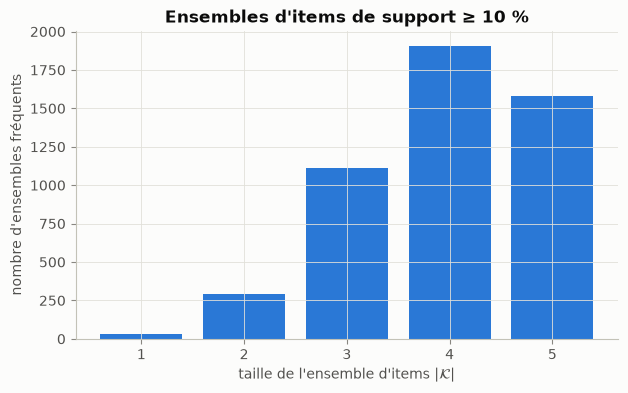

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tailles.index, tailles.values, color=BLUE)
ax.set_xlabel("taille de l'ensemble d'items $|\\mathcal{K}|$")
ax.set_ylabel("nombre d'ensembles fréquents")
ax.set_title("Ensembles d'items de support ≥ 10 %")
plt.show()

Formons les règles. Nous gardons les règles à **conséquent unique** et de confiance au moins
80 % : on en obtient environ 6300, du même ordre que les 6288 règles rapportées par le livre
(les réglages exacts du logiciel utilisé par les auteurs ne sont pas précisés).

In [9]:
regles = ns.regles_association(frequents, confiance_min=0.0, noms=noms)
regles1 = regles[(regles.consequent.apply(len) == 1) & (regles.confiance >= 0.8)].copy()
print("Règles (toutes partitions, sans seuil de confiance) :", len(regles))
print("Règles à conséquent unique, confiance ≥ 0,8 :", len(regles1))

Règles (toutes partitions, sans seuil de confiance) : 81390
Règles à conséquent unique, confiance ≥ 0,8 : 6343


### 2.6 Figure 14.2 : fréquence des items dans les données et dans les règles

Le livre compare la fréquence relative de chaque indicatrice dans les données (proportion
des 1, normalisée pour sommer à 1) et parmi les items apparaissant dans les règles.

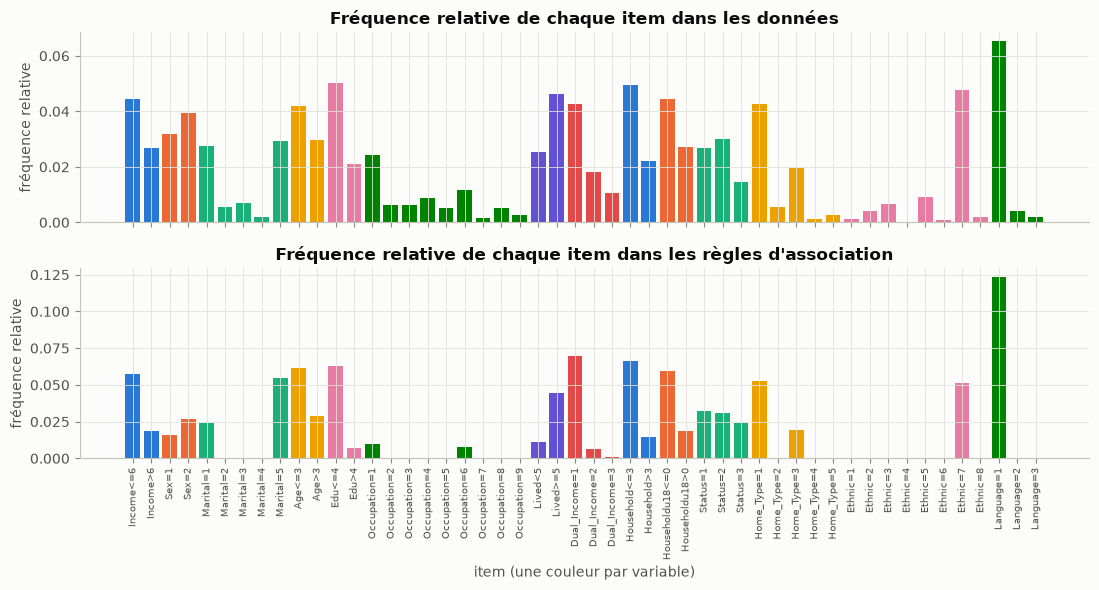

In [10]:
freq_donnees = Z.sum(0) / Z.sum()
compte = pd.Series(0.0, index=noms)
for A, B in zip(regles1.antecedent, regles1.consequent):
    for it in A + B:
        compte[it] += 1
freq_regles = compte / compte.sum()

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
couleur_var = {v: COLORS[i % len(COLORS)] for i, v in enumerate(dict.fromkeys(variables))}
cols = [couleur_var[v] for v in variables]
axes[0].bar(range(50), freq_donnees, color=cols)
axes[0].set_ylabel("fréquence relative")
axes[0].set_title("Fréquence relative de chaque item dans les données")
axes[1].bar(range(50), freq_regles.values, color=cols)
axes[1].set_ylabel("fréquence relative")
axes[1].set_title("Fréquence relative de chaque item dans les règles d'association")
axes[1].set_xticks(range(50))
axes[1].set_xticklabels(noms, rotation=90, fontsize=7)
axes[1].set_xlabel("item (une couleur par variable)")
plt.tight_layout()
plt.show()

Comme dans le livre, les modalités **fréquentes** (langue anglaise, origine « blanc », foyer
de petite taille…) sont sur-représentées dans les règles, tandis que les modalités rares
(la plupart des professions, sauf « cadre » et quelques autres) en sont absentes : un item de
support inférieur à 10 % ne peut figurer dans aucune règle.

### 2.7 Interroger la base de règles

Le livre suggère de stocker les règles dans une base que l'on interroge. Écrivons une petite
fonction d'interrogation, qui traduit au passage les codes en libellés lisibles.

In [11]:
def libelle(item):
    """Traduit un item comme 'Status=1' en texte lisible."""
    for op in ("<=", ">=", "<", ">", "="):
        if op in item:
            v, val = item.split(op)
            break
    val = int(float(val))
    if op == "=" and v in ns.MODALITES_MARKETING:
        return "%s = %s" % (v, ns.MODALITES_MARKETING[v][val])
    return "%s %s %d" % (v, op, val)


def afficher(df, n=5):
    for _, r in df.head(n).iterrows():
        print("  SI   " + "  ET  ".join(libelle(a) for a in r.antecedent))
        print("  ALORS " + " ET ".join(libelle(b) for b in r.consequent))
        print("        support %.1f %%, confiance %.1f %%, lift %.2f\n"
              % (100 * r.support, 100 * r.confiance, r.lift))

**Règle de fort support menant à la langue anglaise** (analogue de la règle 1 du livre :
« foyer de petite taille, sans enfant ⇒ anglais à la maison »).

In [12]:
afficher(regles1[(regles1.consequent == ("Language=1",)) & (regles1.taille == 3)]
         .sort_values("support", ascending=False), n=2)

  SI   Household <= 3  ET  Householdu18 <= 0
  ALORS Language = anglais
        support 52.1 %, confiance 94.2 %, lift 1.03

  SI   Household <= 3  ET  Ethnic = blanc
  ALORS Language = anglais
        support 49.4 %, confiance 98.8 %, lift 1.08



Le lift est proche de 1 : 91 % des personnes interrogées parlent anglais à la maison, la règle
a donc une forte confiance « mécaniquement ».

**Règles menant à un revenu élevé** (analogue de la règle 2 du livre, utile pour cibler des
clients aisés).

In [13]:
afficher(regles1[regles1.consequent == ("Income>6",)].sort_values("confiance", ascending=False), n=3)

  SI   Marital = marié  ET  Occupation = cadre/profession libérale  ET  Status = propriétaire
  ALORS Income > 6
        support 10.4 %, confiance 87.5 %, lift 2.32

  SI   Marital = marié  ET  Occupation = cadre/profession libérale  ET  Home_Type = maison
  ALORS Income > 6
        support 10.4 %, confiance 84.1 %, lift 2.23

  SI   Marital = marié  ET  Dual_Income = oui  ET  Status = propriétaire  ET  Language = anglais
  ALORS Income > 6
        support 11.8 %, confiance 83.0 %, lift 2.20



**Règles menant à un niveau d'études sans diplôme universitaire** (analogue de la règle 3 du
livre).

In [14]:
afficher(regles1[regles1.consequent == ("Edu<=4",)].sort_values("support", ascending=False), n=2)

  SI   Income <= 6
  ALORS Edu <= 4
        support 50.2 %, confiance 80.6 %, lift 1.14

  SI   Income <= 6  ET  Dual_Income = non marié
  ALORS Edu <= 4
        support 37.3 %, confiance 80.6 %, lift 1.14



### 2.8 Support, confiance et lift : un nuage de règles

Chaque point est une règle à conséquent unique et de confiance ≥ 80 %.

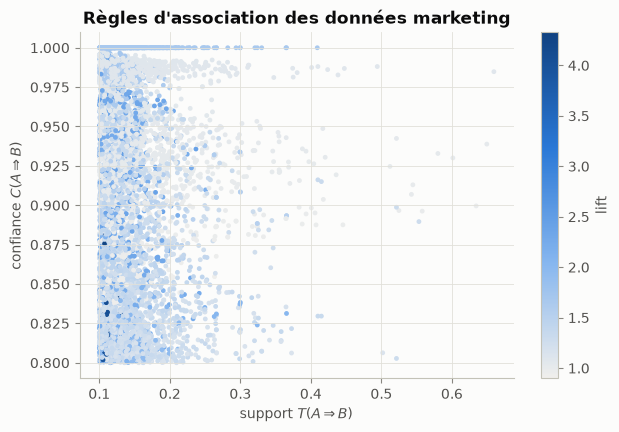

In [15]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(regles1.support, regles1.confiance, c=regles1.lift, cmap=SEQ, s=6)
plt.colorbar(sc, ax=ax, label="lift")
ax.set_xlabel("support $T(A \\Rightarrow B)$")
ax.set_ylabel("confiance $C(A \\Rightarrow B)$")
ax.set_title("Règles d'association des données marketing")
plt.show()

Les règles à fort lift ont un support faible (proche du seuil de 10 %) : ce sont des
associations « intéressantes » mais rares.

> **Remarque.** C'est la principale limite d'Apriori : le seuil de support est indispensable
> au calcul, mais il empêche de découvrir des règles de forte confiance et de fort lift
> portant sur des items rares (l'exemple du livre : « vodka ⇒ caviar », invisible car le caviar
> se vend peu). Baisser le seuil fait exploser le nombre d'ensembles candidats.

Vérifions numériquement l'explosion du nombre d'ensembles fréquents quand le seuil baisse
(on se limite à des ensembles de taille ≤ 3 pour garder un temps de calcul raisonnable).

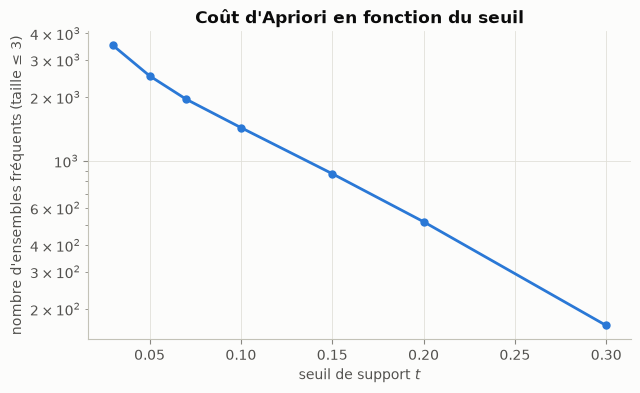

In [16]:
seuils = [0.30, 0.20, 0.15, 0.10, 0.07, 0.05, 0.03]
nb = [len(ns.apriori(Z, s, taille_max=3)) for s in seuils]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(seuils, nb, "o-", color=BLUE)
ax.set_yscale("log")
ax.set_xlabel("seuil de support $t$")
ax.set_ylabel("nombre d'ensembles fréquents (taille ≤ 3)")
ax.set_title("Coût d'Apriori en fonction du seuil")
plt.show()

> **À retenir.** Les règles d'association décrivent des régions de forte probabilité par des
> conjonctions d'items. Apriori trouve **exhaustivement** tous les ensembles d'items de support
> supérieur à $t$ grâce à l'anti-monotonie du support ; la confiance estime $\Pr(B\mid A)$ et le
> lift mesure l'écart à l'indépendance.

## 3. L'apprentissage non supervisé vu comme un problème supervisé

### 3.1 Le principe (section 14.2.4)

Soit $g$ la densité inconnue des données et $g_0$ une densité de **référence** choisie par
nous (par exemple uniforme sur un pavé contenant les données). On tire un échantillon de
taille $N_0$ selon $g_0$ (simulation de Monte-Carlo), on étiquette $Y = 1$ les données
réelles et $Y = 0$ les données simulées, et on réunit les deux échantillons.

Supposons $N_0 = N$. Dans l'échantillon réuni, une observation tirée au hasard vient de $g$
avec probabilité $1/2$ et de $g_0$ avec probabilité $1/2$ : elle suit la densité de mélange
$\frac12 g + \frac12 g_0$. Par la **formule de Bayes**,

$$\mu(x) = \mathbb{E}(Y \mid X = x) = \Pr(Y = 1 \mid X = x)
  = \frac{\frac12 g(x)}{\frac12 g(x) + \frac12 g_0(x)} = \frac{g(x)}{g(x) + g_0(x)}
  = \frac{g(x)/g_0(x)}{1 + g(x)/g_0(x)},$$

c'est l'éq. (14.10) du livre.

La fonction $\mu$ est une fonction de régression ordinaire : on peut l'estimer par n'importe
quelle méthode supervisée (régression logistique, arbres, …) à partir de l'échantillon réuni
(14.11). Puis on **inverse** la relation : de $\mu = \frac{g}{g + g_0}$ on tire
$\mu g + \mu g_0 = g$, soit $g(1 - \mu) = \mu g_0$ et

$$\hat g(x) = g_0(x)\, \frac{\hat\mu(x)}{1 - \hat\mu(x)} \qquad \text{(éq. (14.12)).}$$

La **régression logistique** est particulièrement adaptée, car elle modélise directement le
logarithme du rapport des cotes :

$$f(x) = \log \frac{\mu(x)}{1 - \mu(x)} = \log \frac{g(x)}{g_0(x)}
\quad\text{(14.13)}, \qquad \text{d'où}\quad \hat g(x) = g_0(x)\, e^{\hat f(x)}
\quad\text{(14.14)}.$$

> **Remarque.** Si $N_0 \neq N$, le même calcul donne $\mu/(1-\mu) = (N/N_0)\, g/g_0$ : il suffit
> de corriger la constante.

### 3.2 Reproduction de la figure 14.3

On simule 200 points en forme de croissant, puis 200 points de référence uniformes sur le
rectangle qui contient les données.

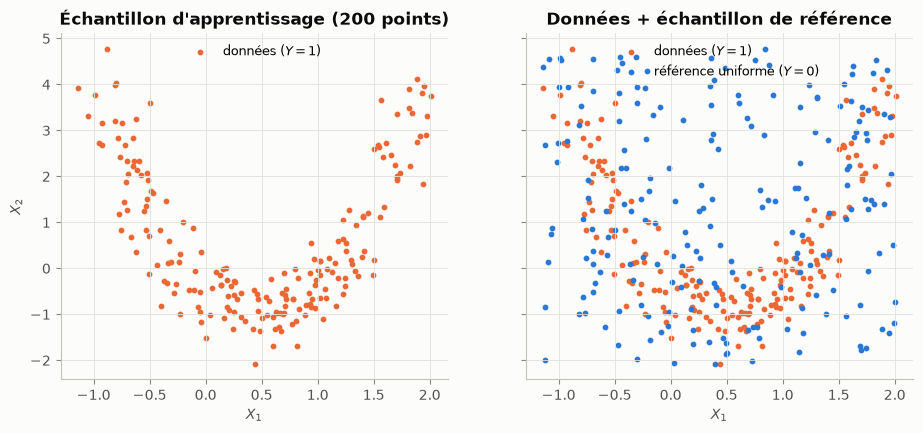

In [17]:
rng = np.random.RandomState(0)
n = 200
u = rng.uniform(-1, 2, n)
Xc = np.column_stack([u + 0.15 * rng.normal(size=n),
                      2.25 * (u - 0.5) ** 2 - 1 + 0.4 * rng.normal(size=n)])
X0 = ns.echantillon_reference(Xc, "uniforme", rng)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
axes[0].scatter(*Xc.T, s=10, color=ORANGE, label="données ($Y=1$)")
axes[0].set_title("Échantillon d'apprentissage (200 points)")
axes[1].scatter(*Xc.T, s=10, color=ORANGE, label="données ($Y=1$)")
axes[1].scatter(*X0.T, s=10, color=BLUE, label="référence uniforme ($Y=0$)")
axes[1].set_title("Données + échantillon de référence")
for ax in axes:
    ax.set_xlabel("$X_1$")
    ax.legend(loc="upper center")
axes[0].set_ylabel("$X_2$")
plt.show()

Comme le livre, on ajuste une **régression logistique** sur une base de **produit tensoriel
de splines cubiques naturelles** (section 5.2.1) : si $N_1, \dots, N_4$ est une base de splines
naturelles en $X_1$ (4 nœuds) et $M_1, \dots, M_4$ en $X_2$, on utilise les 16 fonctions
$N_a(x_1) M_b(x_2)$. Une légère pénalité ridge stabilise l'ajustement (algorithme IRLS de la
section 4.4, fonction `ns.regression_logistique`).

In [18]:
XX = np.vstack([Xc, X0])
yy = np.r_[np.ones(n), np.zeros(n)]
noeuds1 = np.quantile(XX[:, 0], [0.05, 0.35, 0.65, 0.95])
noeuds2 = np.quantile(XX[:, 1], [0.05, 0.35, 0.65, 0.95])


def base_tensorielle(P):
    B1 = ns.base_splines_naturelles(P[:, 0], noeuds1)
    B2 = ns.base_splines_naturelles(P[:, 1], noeuds2)
    return np.einsum("ij,ik->ijk", B1, B2).reshape(len(P), -1)


beta = ns.regression_logistique(base_tensorielle(XX), yy, lam=1.0)
print("Nombre de fonctions de base :", len(beta))

Nombre de fonctions de base : 16


On trace quelques lignes de niveau de $\hat\mu(x)$. Comme $\hat g = g_0\,\hat\mu/(1-\hat\mu)$
avec $g_0$ constante sur le rectangle, ce sont aussi des lignes de niveau de la densité
estimée $\hat g$ (fonction croissante de $\hat\mu$).

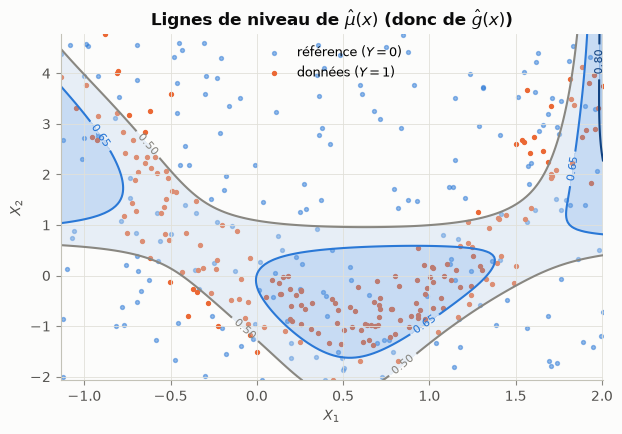

In [19]:
lo, hi = XX.min(0), XX.max(0)
g1, g2 = np.meshgrid(np.linspace(lo[0], hi[0], 150), np.linspace(lo[1], hi[1], 150))
grille = np.c_[g1.ravel(), g2.ravel()]
mu_grille = 1 / (1 + np.exp(-base_tensorielle(grille) @ beta))
aire = np.prod(hi - lo)
g_chapeau = (1 / aire) * mu_grille / (1 - mu_grille)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(*X0.T, s=8, color=BLUE, alpha=0.5, label="référence ($Y=0$)")
ax.scatter(*Xc.T, s=8, color=ORANGE, label="données ($Y=1$)")
ax.contourf(g1, g2, mu_grille.reshape(g1.shape), levels=[0.5, 0.65, 0.8, 0.9, 1.0],
            cmap=SEQ, alpha=0.35)
cs = ax.contour(g1, g2, mu_grille.reshape(g1.shape), levels=[0.5, 0.65, 0.8, 0.9],
                colors=[GRAY, BLUE, "#104281", "#0b0b0b"], linewidths=1.5)
ax.clabel(cs, fmt="%.2f", fontsize=8)
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.set_title("Lignes de niveau de $\\hat\\mu(x)$ (donc de $\\hat g(x)$)")
ax.legend(loc="upper center")
plt.show()

Les lignes de niveau épousent grossièrement le croissant : la classification « données contre
référence » a bien estimé la densité. Vérifions que $\hat g$ est approximativement une densité
(son intégrale sur le rectangle devrait être proche de 1, puisque la régression logistique
reproduit les proportions des deux classes).

In [20]:
pas = (g1[0, 1] - g1[0, 0]) * (g2[1, 0] - g2[0, 0])
print("Intégrale de g chapeau sur le rectangle : %.3f" % (g_chapeau.sum() * pas))

Intégrale de g chapeau sur le rectangle : 0.911


### 3.3 Le choix de la densité de référence

En théorie, n'importe quelle $g_0$ convient ; en pratique, $\mu$ et $f$ sont des **contrastes**
qui mesurent l'écart entre $g$ et $g_0$, et le bon choix dépend de l'écart qui nous intéresse :

* $g_0$ **uniforme** : on détecte les écarts à l'uniformité (zones de forte densité) ;
* $g_0$ **gaussienne** de même moyenne et covariance que les données : écarts à la normalité ;
* $g_0 = \prod_{j} g_j(x_j)$, **produit des lois marginales** (éq. (14.15)) : écarts à
  l'**indépendance** des variables.

Un échantillon de la loi produit (14.15) s'obtient sans connaître les $g_j$ : on **permute
aléatoirement et indépendamment** chaque colonne de la matrice des données. Chaque colonne
garde exactement ses valeurs (donc sa loi marginale empirique), mais les liens entre colonnes
sont détruits.

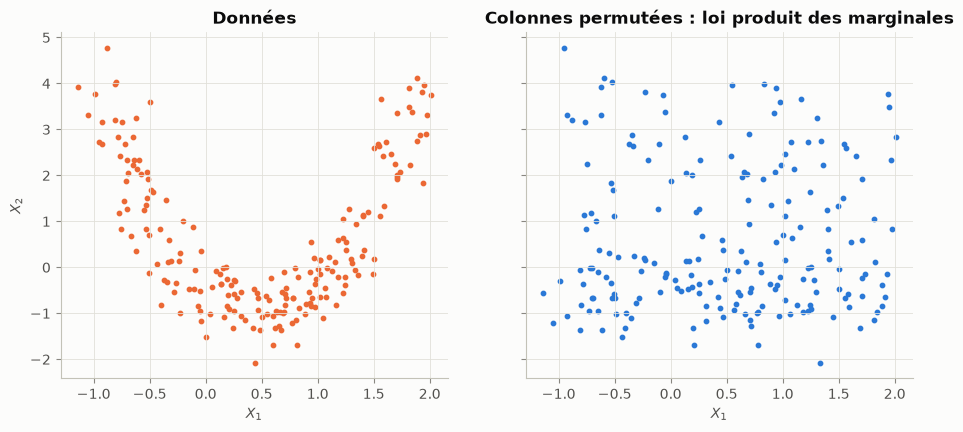

In [21]:
Xperm = ns.echantillon_reference(Xc, "permutation", rng)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
axes[0].scatter(*Xc.T, s=10, color=ORANGE)
axes[0].set_title("Données")
axes[1].scatter(*Xperm.T, s=10, color=BLUE)
axes[1].set_title("Colonnes permutées : loi produit des marginales")
for ax in axes:
    ax.set_xlabel("$X_1$")
axes[0].set_ylabel("$X_2$")
plt.show()

Les histogrammes de $X_1$ et de $X_2$ sont identiques dans les deux panneaux ; seule la forme
conjointe (le croissant) a disparu. Un classifieur qui distingue les deux nuages détecte donc
uniquement la **dépendance** entre $X_1$ et $X_2$.

> **Remarque.** Doubler la taille de l'échantillon (on ajoute $N_0 \ge N$ points simulés) a
> longtemps freiné cette approche, mais c'est aujourd'hui un coût modeste.

## 4. Règles d'association généralisées

### 4.1 Retour au problème général (14.2)

L'analyse du panier n'autorise que des conditions du type « $X_j$ = une valeur ». Le problème
général (14.2) autorise des sous-ensembles $s_j$ quelconques : des **intervalles** pour les
variables quantitatives ou ordinales, des **groupes de modalités** pour les variables
catégorielles. On cherche des « ensembles d'items généralisés » $\bigcap_{j \in \mathcal{J}}
\{X_j \in s_j\}$ de support empirique élevé (éq. (14.16)).

Une recherche exhaustive est impossible : on recourt à des heuristiques.

### 4.2 Lien avec l'apprentissage supervisé

Apriori favorise implicitement les conjonctions de modalités **marginalement fréquentes**
(14.17) : il compare implicitement à une référence **uniforme**. Avec la référence produit des
marginales, le rapport $g/g_0$ est constant en l'absence de toute association, quelle que soit
la fréquence des modalités ; c'est ce qui permettrait à des règles comme « vodka ⇒ caviar »
d'émerger.

Une fois $g_0$ choisie et l'échantillon réuni (14.11) formé, on cherche des régions

$$R = \bigcap_{j \in \mathcal{J}} \{X_j \in s_j\} \qquad (14.18)$$

où $\mu(x) = \mathbb{E}(Y \mid x)$ est grande, avec un support $T(R) = \int_R g(x)\,dx$
(14.19) pas trop petit.

### 4.3 Choix de la méthode supervisée : CART ou PRIM

Les régions (14.18) sont des conjonctions de conditions sur une variable à la fois : c'est
exactement la forme des **feuilles d'un arbre CART** et des **boîtes de PRIM** (section 9.3).

* CART modélise $\mu$ sur tout l'espace ; les feuilles de moyenne $\bar y_t$ élevée sont des
  candidates, de support $T(R) = \bar y_t \cdot N_t/(N + N_0)$.
* PRIM cherche directement une boîte de grande moyenne en « épluchant » à chaque étape une
  petite tranche sur une variable, ce qui donne un meilleur contrôle du compromis
  support / moyenne.

Notre fonction `ns.prim_peeling` implémente la phase d'épluchage de PRIM, avec des
intervalles pour les variables ordinales et le retrait d'une modalité à la fois pour les
variables catégorielles.

### 4.4 PRIM sur les données `marketing` avec une référence uniforme

Tirons chaque variable uniformément parmi ses modalités observées, indépendamment des autres :
c'est la loi uniforme sur la grille des valeurs possibles.

In [22]:
Xm = mk.to_numpy(float)
N = len(Xm)
ref_unif = np.column_stack([rng.choice(np.unique(Xm[:, j]), N) for j in range(Xm.shape[1])])
X_reunies = np.vstack([Xm, ref_unif])
y_reunies = np.r_[np.ones(N), np.zeros(N)]
cat_idx = [list(mk.columns).index(c) for c in ns.CATEGORIELLES_MARKETING]
prim_u = ns.prim_peeling(X_reunies, y_reunies, cat_idx, alpha=0.05, support_min=0.12)


def decrire_boite(boite, colonnes, donnees):
    for c, b, j in zip(colonnes, boite, range(len(colonnes))):
        vals = np.unique(donnees[:, j])
        if b[0] == "modalites" and len(b[1]) < len(vals):
            mods = [ns.MODALITES_MARKETING[c][int(m)] for m in sorted(b[1])]
            print("  %-13s ∈ {%s}" % (c, ", ".join(mods)))
        elif b[0] == "intervalle" and (b[1] > vals.min() or b[2] < vals.max()):
            print("  %-13s ∈ [%g, %g]" % (c, b[1], b[2]))


decrire_boite(prim_u["boite"], mk.columns, Xm)
print("Support dans les données : %.1f %%" % (100 * prim_u["dedans"][:N].mean()))
print("Moyenne de y dans la boîte : %.3f" % prim_u["moyennes"][-1])

  Edu           ∈ [3, 6]
  Dual_Income   ∈ {non marié}
  Household     ∈ [1, 4]
  Householdu18  ∈ [0, 1]
  Status        ∈ {propriétaire, locataire}
  Language      ∈ {anglais}
Support dans les données : 32.4 %
Moyenne de y dans la boîte : 0.989


La boîte trouvée combine surtout des modalités **très fréquentes** (langue anglaise, foyer de
taille modeste, au plus un enfant…) : c'est exactement le biais de la référence uniforme décrit
par le livre, qui favorise les conjonctions de valeurs marginalement fréquentes (14.17). Traçons la trajectoire de l'épluchage.

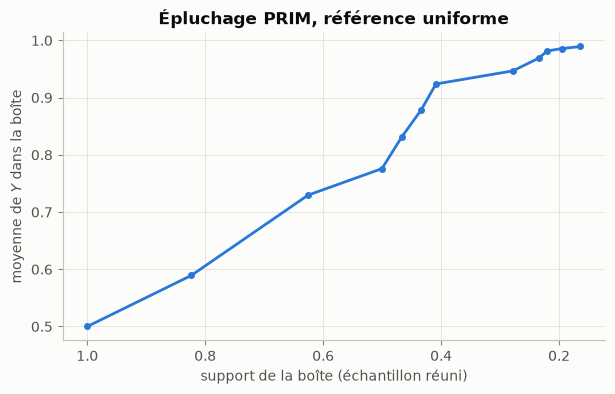

In [23]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(prim_u["supports"], prim_u["moyennes"], "o-", color=BLUE, ms=4)
ax.invert_xaxis()
ax.set_xlabel("support de la boîte (échantillon réuni)")
ax.set_ylabel("moyenne de $Y$ dans la boîte")
ax.set_title("Épluchage PRIM, référence uniforme")
plt.show()